# 病理 patch 到患者建模

按 **Shift+Enter** 从上到下逐单元运行。变量保留在当前内核中；如果修改上游参数，请重新运行其后的单元。

本教程使用固定合成数据，演示软件流程，不提供临床效能结论。需要完整仓库和对应原生安装包；实际源码版本和原生扩展身份请查看本次执行收据。

## 1. 环境与独立输出目录

确认后端为 Rust。后续每步都可以检查中间对象；示例数据生成辅助函数只负责小型输入构造。

In [1]:
from pathlib import Path
import sys, tempfile
from IPython.display import display, Image
# 从 Notebook 所在目录或仓库根目录启动均可。
REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'examples/native/_shared.py').exists()), None)
if REPO is None:
    raise RuntimeError('请先下载完整仓库，并在仓库内启动 Jupyter。')
sys.path.insert(0, str(REPO/'examples/native'))
import ov_radiomics as rad
print(rad.backend_info())
# 每次完整运行使用新目录，避免覆盖已有结果。
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-05_patch_patient-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
root = output
print('输出目录:', output)
import hashlib, importlib.metadata, json, platform
runtime = {'interpreter': sys.executable, 'python': platform.python_version(),
           'package_source': rad.__file__, 'backend': rad.backend_info(),
           'packages': {name: importlib.metadata.version(name) for name in
                        ('ov-radiomics', 'numpy', 'pandas', 'matplotlib', 'ipykernel')}}
from ov_radiomics._backend import try_native
extension = try_native()
if extension is None:
    raise RuntimeError('本教程需要真实 Rust 原生扩展。')
runtime['native_path'] = extension.__file__
runtime['native_sha256'] = hashlib.sha256(Path(extension.__file__).read_bytes()).hexdigest()
runtime['package_python_sha256'] = {p.relative_to(Path(rad.__file__).parent).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                                  for p in sorted(Path(rad.__file__).parent.rglob('*.py'))}
(output/'tutorial-runtime.json').write_text(json.dumps(runtime, ensure_ascii=False, indent=2), encoding='utf-8')
 
import json
import numpy as np
from _shared import GOLDEN, output_arguments, plot_small_overlay, provenance, task_data, write_json, write_rgb_png
import ov_radiomics as rad


{'metrics_backend': 'rust', 'rust_core_version': '0.1.0', 'schema_version': 1, 'api_revision': 2, 'native_compatible': True}
输出目录: /tmp/radiomics-doctrees-8y5ry4nj/tutorials/execution/05_patch_patient/artifacts


## 2. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [2]:
(output / 'images').mkdir()
cases = json.loads((GOLDEN / 'pathology_inputs.json').read_text())
data, _, classes = task_data('binary')
rows = []
vectors = []

## 3. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [3]:
qc_rows = []
parents = {}
statuses = {}
names = ['rgb_R_mean', 'rgb_G_mean', 'rgb_B_mean', 'hue_resultant_length', 'tissue_fraction']
labels = data[['patient_id', 'target', 'group']].drop_duplicates('patient_id')

## 4. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [4]:
for patient, group in data.groupby('patient_id', sort=False):
    for index, (_, row) in enumerate(group.iterrows()):
        slide = patient + '-S' + str(index)
        parents[slide] = patient
        statuses[slide] = 'provided'
        yy, xx = np.indices((8, 8))
        base = np.array([120 + 15 * row.signal_a, 80 + 12 * row.signal_b, 135 + 10 * row.noise_a])
        pixels = np.clip(base + (xx + 2 * yy)[..., None], 0, 255).astype(np.uint8)
        path = output / 'images' / (slide + '.png')
        write_rgb_png(path, pixels)
        patches = rad.pathology.tile_image(path, patient_id=patient, slide_id=slide, patch_size=(4, 4), stride=(4, 4), mpp_x_um=0.5, mpp_y_um=0.5)
        for patch in rad.pathology.qc_patches(patches, config={'max_white_fraction': 0.8}):
            colors = rad.pathology.color_features(patch, config={'fixed_edges': cases['fixed_edges']})
            rows.append(patch.record)
            vectors.append([colors['channels'][channel]['statistics']['mean'] for channel in ('R', 'G', 'B')] + [None if colors['hue'] is None else colors['hue']['resultant_length'], patch.qc['scores']['tissue_fraction']])
            qc_rows.append(dict(tile_id=patch.record['tile_id'], qc=patch.qc, colors=colors))
path = output / 'images/QC-empty.png'
write_rgb_png(path, np.full((4, 4, 3), 255, dtype=np.uint8))
patch = next(rad.pathology.qc_patches(rad.pathology.tile_image(path, patient_id='QC-empty', slide_id='QC-empty', patch_size=(4, 4)), config={'max_white_fraction': 0.8}))
rows.append(patch.record)

## 5. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [5]:
vectors.append([None] * len(names))
parents['QC-empty'] = 'QC-empty'
statuses['QC-empty'] = 'all_excluded'
qc_rows.append(dict(tile_id=patch.record['tile_id'], qc=patch.qc, colors=None))

## 6. 按 tile ID 绑定特征

输入必须明确 tile ID、患者/切片层级及坐标。行数相同不能证明 embedding 对齐。

In [6]:
table = rad.interop.from_arrays(np.asarray(vectors, dtype=float), tile_ids=[row['tile_id'] for row in rows], feature_names=names, tiles=dict(tiles=rows, features=None, feature_names=[], slide_patients=parents, slide_status=statuses))
write_json(output / 'tiles.json', table.to_dict())
with (output / 'qc-colors.jsonl').open('w', encoding='utf-8') as handle:
    for row in qc_rows:
        handle.write(json.dumps(row, allow_nan=False) + '\n')

## 7. 从 tile 聚合到患者

默认先 tile→slide，再切片等权→patient。全被排除的切片保留空状态，不生成零向量。

In [7]:
aggregated = rad.pathology.aggregate(table, patient_stats=['mean'])
write_json(output / 'aggregation.json', aggregated.report)
aggregated.slide_features.save(output / 'slide-features.parquet')
aggregated.patient_features.save(output / 'patient-features.csv')
status = aggregated.patients[['patient_id', 'status']]

## 8. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [8]:
empty = status.loc[status.patient_id == 'QC-empty'].iloc[0]
assert empty.status != 'ok'

## 9. 准备患者级建模表

用患者 ID 做一对一结局连接；明确处理无结局或空结果，不静默补零。

In [9]:
patients = aggregated.patient_features.features.merge(labels, left_on='ID', right_on='patient_id', validate='one_to_one')
features = ['patient_mean(slide_tile_mean(' + name + '))' for name in names[:3]]
if hasattr(patients, 'head'):
    display(patients.head())

,ID,patient_mean(slide_tile_mean(rgb_R_mean)),patient_mean(slide_tile_std(rgb_R_mean)),patient_mean(slide_tile_max(rgb_R_mean)),patient_mean(slide_tile_q25(rgb_R_mean)),patient_mean(slide_tile_q50(rgb_R_mean)),patient_mean(slide_tile_q75(rgb_R_mean)),patient_mean(slide_tile_mean(rgb_G_mean)),patient_mean(slide_tile_std(rgb_G_mean)),patient_mean(slide_tile_max(rgb_G_mean)),...,patient_mean(slide_tile_q75(hue_resultant_length)),patient_mean(slide_tile_mean(tissue_fraction)),patient_mean(slide_tile_std(tissue_fraction)),patient_mean(slide_tile_max(tissue_fraction)),patient_mean(slide_tile_q25(tissue_fraction)),patient_mean(slide_tile_q50(tissue_fraction)),patient_mean(slide_tile_q75(tissue_fraction)),patient_id,target,group
0,binary-P000,146.5,4.472136,152.5,143.5,146.5,149.5,95.0,4.472136,101.0,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,binary-P000,negative,train
1,binary-P001,137.0,4.472136,143.0,134.0,137.0,140.0,92.0,4.472136,98.0,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,binary-P001,positive,train
2,binary-P002,108.5,4.472136,114.5,105.5,108.5,111.5,96.0,4.472136,102.0,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,binary-P002,negative,train
3,binary-P003,149.0,4.472136,155.0,146.0,149.0,152.0,112.0,4.472136,118.0,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,binary-P003,positive,train
4,binary-P004,130.0,4.472136,136.0,127.0,130.0,133.0,89.5,4.472136,95.5,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,binary-P004,negative,train


## 10. 执行原生分析并检查结果

阅读本单元的核心调用与参数。模型训练只使用训练队列；评价时显式保留患者单位和队列身份。

In [10]:
result = rad.train_models(patients, 'target', features, task='binary', classes=classes, positive_label=classes[1], fit_unit='patient', scoring_unit='patient', patient_id='patient_id', cv=3, inner_cv=2, selector=rad.FeatureSelector(backend='rust', univariate=None, lasso=False), backend='rust')
result.save(output / 'patient-model')
rad.evaluate(result, ci_method=None).to_csv(output / 'patient-metrics.csv', index=False)
first_slide = next(iter(parents))
rad.pathology.rasterize_predictions(table, feature='rgb_R_mean', slide_id=first_slide, canvas=dict(width=8, height=8, origin0=[0.0, 0.0], pixel_size0=[1.0, 1.0]), block_size=(4, 4)).save(output / 'tile-feature-overlay')

{'schema': 'radiomics.overlay.v1',
 'coordinate_space': 'level0_pixel_edges',
 'canvas': {'width': 8,
  'height': 8,
  'origin0': [0.0, 0.0],
  'pixel_size0': [1.0, 1.0]},
 'blocks': [{'x': 0,
   'y': 0,
   'width': 4,
   'height': 4,
   'origin0': [0.0, 0.0],
   'pixel_size0': [1.0, 1.0],
   'path': 'block-000000000000-000000000000.npz'},
  {'x': 4,
   'y': 0,
   'width': 4,
   'height': 4,
   'origin0': [4.0, 0.0],
   'pixel_size0': [1.0, 1.0],
   'path': 'block-000000000000-000000000004.npz'},
  {'x': 0,
   'y': 4,
   'width': 4,
   'height': 4,
   'origin0': [0.0, 4.0],
   'pixel_size0': [1.0, 1.0],
   'path': 'block-000000000004-000000000000.npz'},
  {'x': 4,
   'y': 4,
   'width': 4,
   'height': 4,
   'origin0': [4.0, 4.0],
   'pixel_size0': [1.0, 1.0],
   'path': 'block-000000000004-000000000004.npz'}],
 'algorithm': 'native global-index pixel-center sampling; half-open rectangles; overlap mean',
 'provenance': {'input_configuration_sha256': '7f934518738e9003c4321a8e8e6d2df36e1

## 11. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [11]:
plot_small_overlay(output / 'tile-feature-overlay', output / 'tile-feature-overlay.png', value_label='RGB R mean (8-bit)')

## 12. 已有分割 mask 统计

区分 instance 与 semantic mask。这里的对象数是 patch 级；没有全局实例 ID 时不能把重叠 patch 计数相加。

In [12]:
objects = rad.pathology.object_features(np.array([[1, 1, 0, 2], [1, 0, 0, 2], [0, 0, 0, 0], [0, 0, 0, 0]], dtype=np.uint32), kind='instance', connectivity=4, patch_mpp_um=(0.5, 0.5), overlapping_tiles=True)
assert objects['count_scope'] == 'patch_local'
write_json(output / 'patch-objects.json', objects)
provenance(output, '05_patch_patient', patients=len(patients), tiles=len(table), empty_patients_retained=['QC-empty'], modeling_exclusion='QC-empty has no study outcome; explicitly omitted from identified modeling join', aggregation='tile→slide, then equal-slide patient mean', overlay='actual tile RGB feature; patient probabilities are never local scores', hue='angles remain patch display statistics; only resultant length is aggregated')
print(rad.evaluate(result, ci_method=None).to_string(index=False))

model      group   task prediction_unit  n prediction_type          status  positive_n  threshold  accuracy      auc  sensitivity  specificity      ppv     npv  precision   recall       f1    brier  log_loss_eps1e15  average_precision  pr_auc_trapezoidal  ci_low  ci_high
   LR external_A binary         patient  6        external prediction_only         NaN        NaN       NaN      NaN          NaN          NaN      NaN     NaN        NaN      NaN      NaN      NaN               NaN                NaN                 NaN     NaN      NaN
   LR       test binary         patient 12         holdout       evaluated         6.0        0.5  0.500000 0.777778     0.166667     0.833333 0.500000 0.50000   0.500000 0.166667 0.250000 0.207773          0.600880           0.775000            0.743519     NaN      NaN
   LR      train binary         patient 48        apparent       evaluated        24.0        0.5  0.645833 0.718750     0.583333     0.708333 0.666667 0.62963   0.666667 0.583333 0.62

## 13. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [13]:
print('Outputs:', output)

Outputs: /tmp/radiomics-doctrees-8y5ry4nj/tutorials/execution/05_patch_patient/artifacts


## 查看导出的图与文件

查看图表的坐标、单位和预测层级。输出目录保留完整结果；这里显示前两幅图。

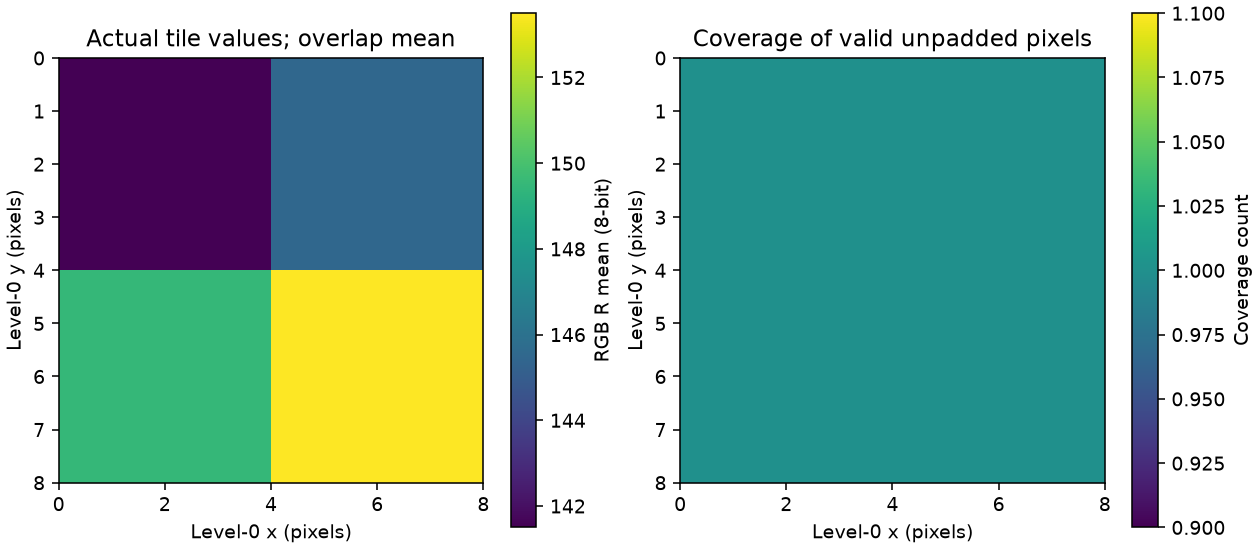

结果文件: ['aggregation.json', 'images', 'patch-objects.json', 'patient-features.csv', 'patient-features.csv.manifest.json', 'patient-metrics.csv', 'patient-model', 'provenance.json', 'qc-colors.jsonl', 'slide-features.parquet', 'slide-features.parquet.manifest.json', 'tile-feature-overlay', 'tile-feature-overlay.png', 'tiles.json', 'tutorial-runtime.json']


In [14]:
for figure in sorted(output.glob('*.png'))[:2]:
    display(Image(filename=str(figure)))
print('结果文件:', [p.name for p in sorted(output.iterdir())])

## 换成自己的数据

保持示例的 ID、患者/切片层级与列角色约定，先替换数据读取步骤，再重新运行下游单元。先确认几何、单位、缺失状态和队列重叠；不要用测试集决定阈值或筛选参数。

重新运行全部单元会新建结果目录；只重跑保存单元可能因为文件已存在而报错，这是显式防覆盖行为。